#**TRAINING**

##**Data Preprocessing**

In [ ]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/CHALLENGE1ANN"
%cd $current_dir

Mounted at /gdrive
/gdrive/.shortcut-targets-by-id/1zXlKtIs_l7uErhQ5LyiPQwfRNFrTdsfW/CHALLENGE1ANN


In [ ]:
# Set seed for reproducibility
SEED = 50

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
# from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.8.0+cu126
Device: cuda


In [ ]:
X_train = pd.read_csv('pirate_pain_train.csv')
y_train = pd.read_csv('pirate_pain_train_labels.csv')
X_test = pd.read_csv('pirate_pain_test.csv')

In [ ]:
# since the feature joint_30 is the same value for every sample (0.5) we elimnate it
X_train = X_train.drop('joint_30', axis=1)
X_test = X_test.drop('joint_30', axis=1)

In [ ]:
#Change the datatype of joint columns to float32
# Loop for the joint columns
for i in range(30):
    col_name = f'joint_{i:02d}' # Formatting the column name (es. 'joint_00', 'joint_01')
    if col_name in X_train.columns:
        X_train[col_name] = X_train[col_name].astype(np.float32)
        X_test[col_name] = X_test[col_name].astype(np.float32)

print("Verifying data types after conversion using for loop:")
X_train.info()

#the dataset doesn't seem to have any missing values

Verifying data types after conversion using for loop:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 39 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   105760 non-null  int64  
 1   time           105760 non-null  int64  
 2   pain_survey_1  105760 non-null  int64  
 3   pain_survey_2  105760 non-null  int64  
 4   pain_survey_3  105760 non-null  int64  
 5   pain_survey_4  105760 non-null  int64  
 6   n_legs         105760 non-null  object 
 7   n_hands        105760 non-null  object 
 8   n_eyes         105760 non-null  object 
 9   joint_00       105760 non-null  float32
 10  joint_01       105760 non-null  float32
 11  joint_02       105760 non-null  float32
 12  joint_03       105760 non-null  float32
 13  joint_04       105760 non-null  float32
 14  joint_05       105760 non-null  float32
 15  joint_06       105760 non-null  float32
 16  joint_07       10576

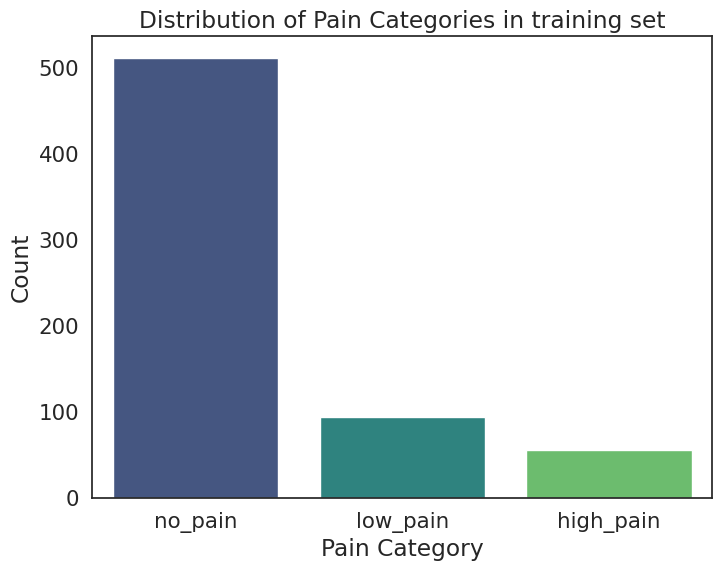

In [ ]:
plt.figure(figsize=(8, 6))
sns.countplot(data=y_train, x='label', palette='viridis')
plt.title('Distribution of Pain Categories in training set')
plt.xlabel('Pain Category')
plt.ylabel('Count')
plt.show()

In [ ]:
columns_to_analyze = ['n_legs', 'n_hands', 'n_eyes']

for col in columns_to_analyze:
    print(f"\nUnique values and counts for column: {col}")
    print(X_train[col].value_counts())


Unique values and counts for column: n_legs
n_legs
two            104800
one+peg_leg       960
Name: count, dtype: int64

Unique values and counts for column: n_hands
n_hands
two              104800
one+hook_hand       960
Name: count, dtype: int64

Unique values and counts for column: n_eyes
n_eyes
two              104800
one+eye_patch       960
Name: count, dtype: int64


In [ ]:
# Define a mapping of n_legs values to integer labels
label_mapping_legs = {
    'two': 0,
    'one+peg_leg': 1,
}
# Map n_legs attributes to integers in the training set
X_train['n_legs'] = X_train['n_legs'].map(label_mapping_legs)
X_test['n_legs'] = X_test['n_legs'].map(label_mapping_legs)

# Define a mapping of n_hands values to integer labels
label_mapping_hands = {
    'two': 0,
    'one+hook_hand': 1,
}
# Map n_hands attributes to integers in the training set
X_train['n_hands'] = X_train['n_hands'].map(label_mapping_hands)
X_test['n_hands'] = X_test['n_hands'].map(label_mapping_hands)

# Define a mapping of n_eyes values to integer labels
label_mapping_eyes = {
    'two': 0,
    'one+eye_patch': 1,
}
# Map n_eyes attributes to integers in the training set
X_train['n_eyes'] = X_train['n_eyes'].map(label_mapping_eyes)
X_test['n_eyes'] = X_test['n_eyes'].map(label_mapping_eyes)

In [ ]:
#expand the original y_train dataset in order to have the label for every timestamp of each sample_index
y_train_expanded = y_train.loc[y_train.index.repeat(160)].reset_index(drop=True)
print(f"Original y_train shape: {y_train.shape}")
print(f"Expanded y_train shape: {y_train_expanded.shape}")

Original y_train shape: (661, 2)
Expanded y_train shape: (105760, 2)


In [ ]:
#add the label to the X_train dataset
X_train_mod = X_train.copy()
X_train_mod['label'] = y_train_expanded['label']

In [ ]:
# Get unique user IDs and shuffle them
unique_users = X_train_mod['sample_index'].unique()
random.seed(SEED) # Ensure reproducibility of shuffling
random.shuffle(unique_users)

# Define the number of users for validation set
N_VAL_USERS = 75 # You can change this number

# Calculate the number of users for the training set
n_train_users = len(unique_users) - N_VAL_USERS

# Split the shuffled user IDs into training, validation, and test sets
train_users = unique_users[:n_train_users]
val_users = unique_users[n_train_users:n_train_users + N_VAL_USERS]

# Split the dataset into training, validation, and test sets based on user IDs
df_train = X_train_mod[X_train_mod['sample_index'].isin(train_users)]
df_val = X_train_mod[X_train_mod['sample_index'].isin(val_users)]

# Print the shapes of the training, validation, and test sets
print(f'Training set shape: {df_train.shape}')
print(f'Validation set shape: {df_val.shape}')

Training set shape: (93760, 40)
Validation set shape: (12000, 40)


In [ ]:
# Initialise a dictionary to count occurrences of each activity in the training set
training_labels = {
    'no_pain': 0,
    'low_pain': 0,
    'high_pain': 0,
}

# Count occurrences of each activity for unique IDs in the training set
for id in df_train['sample_index'].unique():
    label = df_train[df_train['sample_index'] == id]['label'].values[0]
    training_labels[label] += 1

# Print the distribution of training labels
print('Training labels:', training_labels)

Training labels: {'no_pain': 455, 'low_pain': 82, 'high_pain': 49}


In [ ]:
# Initialise a dictionary to count occurrences of each activity in the validation set
val_labels = {
    'no_pain': 0,
    'low_pain': 0,
    'high_pain': 0,
}

# Count occurrences of each activity for unique IDs in the validation set
for id in df_val['sample_index'].unique():
    label = df_val[df_val['sample_index'] == id]['label'].values[0]
    val_labels[label] += 1

# Print the distribution of training labels
print('Validation labels:', val_labels)


Validation labels: {'no_pain': 56, 'low_pain': 12, 'high_pain': 7}


In [ ]:
# Define a mapping of pain values to integer labels
label_mapping_pain = {
    'no_pain': 0,
    'low_pain': 1,
    'high_pain': 2,
}

# Map activity pain levels to integers in the training set
df_train['label'] = df_train['label'].map(label_mapping_pain)

# Map activity pain levels to integers in the validation set
df_val['label'] = df_val['label'].map(label_mapping_pain)

In [ ]:
# Define the columns to be normalised
scale_columns = []
for i in range(30):
    scale_columns.append(f'joint_{i:02d}') # Formatting the column name (es. 'joint_00', 'joint_01')

# Calculate the minimum and maximum values from the training data only
# we normalize with respect to the training set, as we have always done
#this is min-max scaling
mins = df_train[scale_columns].min()
maxs = df_train[scale_columns].max()

# Apply normalisation to the specified columns in all datasets
for column in scale_columns:
    # Normalise the training set
    df_train[column] = (df_train[column] - mins[column]) / (maxs[column] - mins[column])

    # Normalise the validation set
    df_val[column] = (df_val[column] - mins[column]) / (maxs[column] - mins[column])

    # Normalise the test set
    X_test[column] = (X_test[column] - mins[column]) / (maxs[column] - mins[column])

In [ ]:
###########################################
WINDOW_SIZE = 30
STRIDE = 10
###########################################

In [ ]:
# Define a function to build sequences from the dataset
def build_sequences(df, window=20, stride=5):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []
    labels = []

    # Define all columns to be used for building sequences
    all_columns = scale_columns + ["pain_survey_1", "pain_survey_2", "pain_survey_3", "pain_survey_4", "n_legs", "n_hands", "n_eyes"]


    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][all_columns].values

        # Retrieve the activity label for the current ID
        label = df[df['sample_index'] == id]['label'].values[0]

        # Calculate padding length to ensure full windows
        padding_len = window - len(temp) % window

        # Create zero padding and concatenate with the data
        # The padding should match the number of columns being used
        padding = np.zeros((padding_len, len(all_columns)), dtype='float32')
        temp = np.concatenate((temp, padding))


        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            labels.append(label)
            idx += stride

    # Convert lists to numpy arrays for further processing
    dataset = np.array(dataset)
    labels = np.array(labels)

    return dataset, labels

In [ ]:
# Define a function to build sequences from the dataset
def build_sequences_test(df, window=20, stride=5):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []

    # Define all columns to be used for building sequences
    all_columns = scale_columns + ["pain_survey_1", "pain_survey_2", "pain_survey_3", "pain_survey_4", "n_legs", "n_hands", "n_eyes"]

    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][all_columns].values

        # Calculate padding length to ensure full windows
        padding_len = window - len(temp) % window

        # Create zero padding and concatenate with the data
        # The padding should match the number of columns being used
        padding = np.zeros((padding_len, len(all_columns)), dtype='float32')
        temp = np.concatenate((temp, padding))

        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            idx += stride

    # Convert lists to numpy arrays for further processing
    # dataset = np.array(dataset)

    return dataset

In [ ]:
# Generate sequences and labels for the training set
X_train, y_train = build_sequences(df_train, WINDOW_SIZE, STRIDE)

# Generate sequences and labels for the validation set
X_val, y_val = build_sequences(df_val, WINDOW_SIZE, STRIDE)

# Generate sequences for the test set
X_test_windowed = build_sequences_test(X_test, WINDOW_SIZE, STRIDE)


# Print the shapes of the generated datasets and their labels
print(f"Training sequences shape: {X_train.shape}, Labels shape: {y_train.shape}")
print(f"Validation sequences shape: {X_val.shape}, Labels shape: {y_val.shape}")
print(f"Test sequences shape: {np.array(X_test_windowed).shape}")

Training sequences shape: (9376, 30, 37), Labels shape: (9376,)
Validation sequences shape: (1200, 30, 37), Labels shape: (1200,)
Test sequences shape: (21184, 30, 37)


In [ ]:
# Define the input shape based on the training data
input_shape = X_train.shape[1:]

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(y_train))

In [ ]:
# Convert numpy arrays to PyTorch datasets (pairs features with labels)
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))

In [ ]:
# Define the batch size, which is the number of samples in each batch
BATCH_SIZE = 128

In [ ]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [ ]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [ ]:
# Get one batch from the training data loader
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([128, 30, 37])
Labels batch shape: torch.Size([128])


##**Model Building**

In [ ]:
#ORIGINALE
def recurrent_summary(model, input_size):
    """
    Custom summary function that emulates torchinfo's output while correctly
    counting parameters for RNN/GRU/LSTM layers.

    This function is designed for models whose direct children are
    nn.Linear, nn.RNN, nn.GRU, or nn.LSTM layers.

    Args:
        model (nn.Module): The model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    # Dictionary to store output shapes captured by forward hooks
    output_shapes = {}
    # List to track hook handles for later removal
    hooks = []

    def get_hook(name):
        """Factory function to create a forward hook for a specific module."""
        def hook(module, input, output):
            # Handle RNN layer outputs (returns a tuple)
            if isinstance(output, tuple):
                # output[0]: all hidden states with shape (batch, seq_len, hidden*directions)
                shape1 = list(output[0].shape)
                shape1[0] = -1  # Replace batch dimension with -1

                # output[1]: final hidden state h_n (or tuple (h_n, c_n) for LSTM)
                if isinstance(output[1], tuple):  # LSTM case: (h_n, c_n)
                    shape2 = list(output[1][0].shape)  # Extract h_n only
                else:  # RNN/GRU case: h_n only
                    shape2 = list(output[1].shape)

                # Replace batch dimension (middle position) with -1
                shape2[1] = -1

                output_shapes[name] = f"[{shape1}, {shape2}]"

            # Handle standard layer outputs (e.g., Linear)
            else:
                shape = list(output.shape)
                shape[0] = -1  # Replace batch dimension with -1
                output_shapes[name] = f"{shape}"
        return hook

    # 1. Determine the device where model parameters reside
    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")  # Fallback for models without parameters

    # 2. Create a dummy input tensor with batch_size=1
    dummy_input = torch.randn(1, *input_size).to(device)

    # 3. Register forward hooks on target layers
    # Iterate through direct children of the model (e.g., self.rnn, self.classifier)
    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.RNN, nn.GRU, nn.LSTM)):
            # Register the hook and store its handle for cleanup
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    # 4. Execute a dummy forward pass in evaluation mode
    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            # Clean up hooks even if an error occurs
            for h in hooks:
                h.remove()
            return

    # 5. Remove all registered hooks
    for h in hooks:
        h.remove()

    # --- 6. Print the summary table ---

    print("-" * 79)
    # Column headers
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Iterate through modules again to collect and display parameter information
    for name, module in model.named_children():
        if name in output_shapes:
            # Count total and trainable parameters for this module
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            # Format strings for display
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)

##**Model Training**

In [ ]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            # Cast input to float16 for mixed precision training
            inputs = inputs.to(torch.float16)
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [ ]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                inputs = inputs.to(torch.float16) # Add this line
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [ ]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

In [ ]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0
        model_save_path = os.path.join("models", experiment_name + '_model.pt')


    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), model_save_path)
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load(model_save_path))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        model_save_path = os.path.join("models", experiment_name + '_model.pt')
        torch.save(model.state_dict(), model_save_path)
        print(f"Saved final model to {model_save_path}")


    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

In [ ]:
# Training configuration & Architecture params
LEARNING_RATE = 1e-3
EPOCHS = 500
PATIENCE = 100
DROPOUT_RATE = 0.4
L1_LAMBDA = 0
L2_LAMBDA = 1e-4
HIDDEN_SIZE= 256
NUM_LAYERS= 2
DROPOUT_RATE=0.4
DILATATION_SIZE= 2
KERNEL_SIZE=3
WINDOW_SIZE=30
STRIDE = 10
SEED = 1

import torch
from torch import nn
from torch.utils.tensorboard import SummaryWriter

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# Assuming X_train from previous processing is available or its shape is fixed
# For this cell to be self-contained for architecture check, we'll use example values
# In a full run, X_train's actual shape would dictate this.
input_shape = (30, 37) # Example based on previous execution output

k = (455 + 82 + 49) / (3 * 82) # Weight for class 1 (based on the split of labels in the training set) = N(tot samples) / (numero classi * numero samples in classe c) #2
c = (455 + 82 + 49) / (3 * 49) # Weight for class 2 (based on the split of labels in the training set) #3
class_weights = torch.tensor([1.0, k, c], dtype=torch.float32).to(device)

# Set up loss function and optimizer with class weights
criterion = nn.CrossEntropyLoss()
#without weight criteriorn: criterion = nn.CrossEntropyLoss()
#to put weight criterion: criterion = nn.CrossEntropyLoss(weight = class_weights)

# Ensure y_train is defined for num_classes, if not, use a default/example value
# For verification of architecture, a hardcoded num_classes is sufficient if y_train is not directly available here.
# In a complete notebook run, y_train would be processed earlier.
num_classes = 3 # Example based on previous execution output len(np.unique(y_train))

logs_dir = "tensorboard"
# --- End of variable definitions ---

In [ ]:
import torch
from torch import nn
from torch.utils.tensorboard import SummaryWriter

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

input_shape = (30, 37) # Example based on previous execution output

k = (455 + 82 + 49) / (3 * 82) # Weight for class 1 (based on the split of labels in the training set)
c = (455 + 82 + 49) / (3 * 49) # Weight for class 2 (based on the split of labels in the training set)
class_weights = torch.tensor([1.0, k, c], dtype=torch.float32).to(device)

# Set up loss function and optimizer with class weights
criterion = nn.CrossEntropyLoss()
# If class weights were to be used: criterion = nn.CrossEntropyLoss(weight = class_weights)

# Ensure y_train is defined for num_classes, if not, use a default/example value
num_classes = 3 # Example based on previous execution output len(np.unique(y_train))

logs_dir = "tensorboard"

# --- Custom recurrent_summary function ---
def recurrent_summary(model, input_size):
    """
    Custom summary function that emulates torchinfo's output while correctly
    counting parameters for RNN/GRU/LSTM layers.

    This function is designed for models whose direct children are
    nn.Linear, nn.RNN, nn.GRU, or nn.LSTM layers.

    Args:
        model (nn.Module): The model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    output_shapes = {}
    hooks = []

    def get_hook(name):
        def hook(module, input, output):
            if isinstance(output, tuple):
                shape1 = list(output[0].shape)
                shape1[0] = -1

                if isinstance(output[1], tuple):
                    shape2 = list(output[1][0].shape)
                else:
                    shape2 = list(output[1].shape)

                shape2[1] = -1

                output_shapes[name] = f"[{shape1}, {shape2}]"

            else:
                shape = list(output.shape)
                shape[0] = -1
                output_shapes[name] = f"{shape}"
        return hook

    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")

    dummy_input = torch.randn(1, *input_size).to(device)

    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.RNN, nn.GRU, nn.LSTM, nn.Sequential)):
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            for h in hooks:
                h.remove()
            return

    for h in hooks:
        h.remove()

    print("-" * 79)
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    for name, module in model.named_children():
        if name in output_shapes:
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)

class Chomp1d(nn.Module):
    """Removes padding introduced by causal convolution to maintain causality."""
    def __init__(self, chomp_size):
        super().__init__()
        self.chomp_size = chomp_size

    def forward(self, x):
        # Trim the rightmost `chomp_size` elements from the last dimension
        if self.chomp_size == 0:
            return x
        return x[:, :, :-self.chomp_size].contiguous()


class TemporalBlock(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_size, stride, dilation, padding, dropout_rate=0.2):
        super().__init__()
        # First convolutional layer in the block
        conv1 = nn.Conv1d(n_inputs, n_outputs // 4, kernel_size,
                          stride=stride, padding=padding, dilation=dilation)
        chomp1 = Chomp1d(padding)
        relu1 = nn.ReLU()
        dropout1 = nn.Dropout(dropout_rate)

        # Second convolutional layer in the block
        conv2 = nn.Conv1d(n_outputs // 4, n_outputs, kernel_size,
                          stride=stride, padding=padding, dilation=dilation)
        chomp2 = Chomp1d(padding)
        relu2 = nn.ReLU()
        dropout2 = nn.Dropout(dropout_rate)

        # Apply weight_norm to the convolutional layers
        self.conv1 = nn.utils.weight_norm(conv1)
        self.conv2 = nn.utils.weight_norm(conv2)

        self.net = nn.Sequential(self.conv1, chomp1, relu1, dropout1,
                                 self.conv2, chomp2, relu2, dropout2)

    def forward(self, x):
        return self.net(x)

# --- RecurrentClassifier class definition ---
class RecurrentClassifier(nn.Module):
    """
    Generic RNN classifier (RNN, LSTM, GRU).
    Uses the last hidden state for classification.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            num_layers,
            num_classes,
            dilation_size,
            padding,
            kernel_size,
            rnn_type='GRU',        # 'RNN', 'LSTM', or 'GRU'
            bidirectional=False,
            dropout_rate=0.2
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional

        rnn_map = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        if rnn_type not in rnn_map:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        rnn_module = rnn_map[rnn_type]

        dropout_val = dropout_rate if num_layers > 1 else 0

        # New linear layer before RNN
        self.feature_extractor = TemporalBlock(input_size, hidden_size // 2, kernel_size,
                                            stride=1, dilation=dilation_size,
                                            padding=padding, dropout_rate=dropout_rate)


        self.rnn = rnn_module(
            input_size=hidden_size // 2, # Input to RNN is now output of linear layer
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        if self.bidirectional:
            classifier_input_size = hidden_size * 2
        else:
            classifier_input_size = hidden_size

        self.classifier = nn.Linear(classifier_input_size, 3)


    def forward(self, x):
        x = x.to(torch.float32)

        # Apply linear layer before RNN
        # The input x is (batch_size, seq_len, input_size)
        # Linear layer expects (batch_size, input_size), so we apply it to each time step

        x = x.permute(0, 2, 1) # Permute to (batch_size, features, sequence_length)
        features = self.feature_extractor(x)
        features = features.permute(0, 2, 1)

        rnn_out, hidden = self.rnn(features)

        if self.rnn_type == 'LSTM':
            hidden = hidden[0]

        if self.bidirectional:
            hidden = hidden.view(self.num_layers, 2, -1, self.hidden_size)
            hidden_to_classify = torch.cat([hidden[-1, 0, :, :], hidden[-1, 1, :, :]], dim=1)
        else:
            hidden_to_classify = hidden[-1]

        logits = self.classifier(hidden_to_classify)
        return logits
# --- End of RecurrentClassifier class definition ---


# Create model and display architecture with parameter count
rnn_model = RecurrentClassifier(
    input_size=input_shape[-1],
    hidden_size= HIDDEN_SIZE,
    num_layers= NUM_LAYERS,
    num_classes=3,
    dropout_rate=DROPOUT_RATE,
    dilation_size=DILATATION_SIZE,
    padding=1,
    kernel_size=KERNEL_SIZE,
    bidirectional=False,
    rnn_type='LSTM'
    ).to(device)
recurrent_summary(rnn_model, input_size=input_shape)

# Set up TensorBoard logging and save model architecture
experiment_name = "Features"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)


# Define optimizer with L2 regularization
optimizer = torch.optim.AdamW(rnn_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
rnn (LSTM)                [[-1, 24, 256], [2, -1, 256]] 921,600        
classifier (Linear)       [-1, 3]                      771            
Total params: 922,371
Trainable params: 922,371
Non-trainable params: 0
-------------------------------------------------------------------------------


In [ ]:
%%time
# Train model and track training history
rnn_model, training_history = fit(
    model=rnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name=experiment_name,
    patience=PATIENCE
    )

# Update best model if current performance is superior
if training_history['val_f1'][-1] > best_performance:
    best_model = rnn_model
    best_performance = training_history['val_f1'][-1]

Training 500 epochs...
Epoch   1/500 | Train: Loss=0.6886, F1 Score=0.6803 | Val: Loss=0.7525, F1 Score=0.6384
Epoch   2/500 | Train: Loss=0.6058, F1 Score=0.7197 | Val: Loss=0.6747, F1 Score=0.6789
Epoch   3/500 | Train: Loss=0.5699, F1 Score=0.7547 | Val: Loss=0.6104, F1 Score=0.7204
Epoch   4/500 | Train: Loss=0.4681, F1 Score=0.7975 | Val: Loss=0.5653, F1 Score=0.7569
Epoch   5/500 | Train: Loss=0.4506, F1 Score=0.8075 | Val: Loss=0.5111, F1 Score=0.7814
Epoch   6/500 | Train: Loss=0.4234, F1 Score=0.8175 | Val: Loss=0.5329, F1 Score=0.7855
Epoch   7/500 | Train: Loss=0.4195, F1 Score=0.8197 | Val: Loss=0.5080, F1 Score=0.7831
Epoch   8/500 | Train: Loss=0.4018, F1 Score=0.8256 | Val: Loss=0.5515, F1 Score=0.7788
Epoch   9/500 | Train: Loss=0.4073, F1 Score=0.8299 | Val: Loss=0.4369, F1 Score=0.8125
Epoch  10/500 | Train: Loss=0.3861, F1 Score=0.8326 | Val: Loss=0.4560, F1 Score=0.7990
Epoch  11/500 | Train: Loss=0.3687, F1 Score=0.8531 | Val: Loss=0.4081, F1 Score=0.8339
Epoch  12

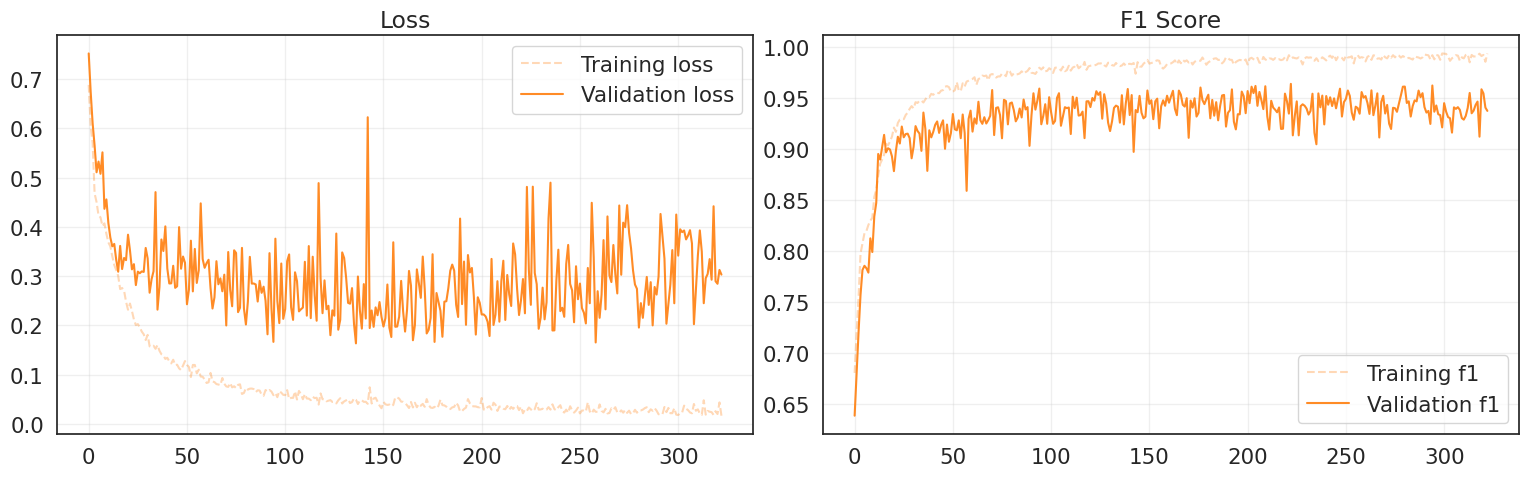

In [ ]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3);

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3);

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.9650
Precision over the validation set: 0.9651
Recall over the validation set: 0.9650
F1 score over the validation set: 0.9642


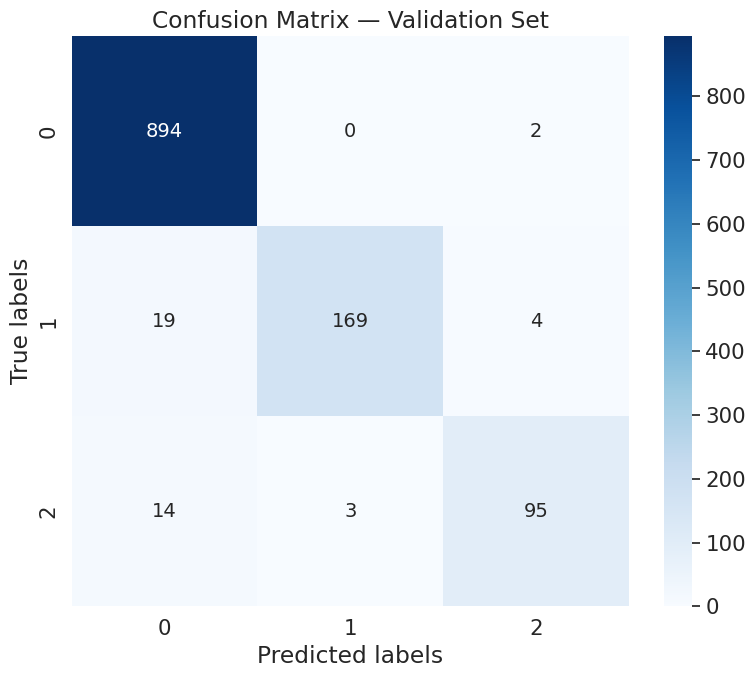

In [ ]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = rnn_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

In [ ]:
# @title Model Reloading

# The RecurrentClassifier class is moved here for self-containment.
# Questa classe definisce l'architettura del modello RNN/LSTM/GRU.
from math import floor # Aggiungi questa riga per importare la funzione floor
import os # Assicurati che os sia importato se usato da make_loader


# --- Parametri di Windowing e Batching (Coerenti con Training/Validation) ---
# Questi dovrebbero corrispondere a quelli usati per addestrare il modello
WINDOW_SIZE = 30
STRIDE = 10
BATCH_SIZE = 128

# Definizione delle colonne feature (assumendo che 'scale_columns' sia globale e definito in precedenza)
feature_columns = scale_columns + ["pain_survey_1", "pain_survey_2", "pain_survey_3", "pain_survey_4", "n_legs", "n_hands", "n_eyes"]

# Calcola il numero di feature (input_size per il modello)
input_size = len(feature_columns)

# --- 1. Genera *tutte* le sottosequenze da X_test usando build_sequences_test ---
# Assicurati che build_sequences_test sia definito e accessibile (è una funzione globale nel notebook)
# X_test è già stato pre-processato e normalizzato nelle celle precedenti.

print("Generazione di tutte le sottosequenze da X_test...")
X_test_all_windowed = build_sequences_test(X_test, window=WINDOW_SIZE, stride=STRIDE)

# Converti in numpy array per compatibilità con TensorDataset
X_test_all_windowed = np.array(X_test_all_windowed)

print(f"Numero totale di sottosequenze generate per tutti i campioni: {X_test_all_windowed.shape[0]}")
print(f"Shape di una sottosequenza: {X_test_all_windowed.shape[1:]}")

# Crea il DataLoader per tutte le sottosequenze
all_sequences_ds = TensorDataset(torch.from_numpy(X_test_all_windowed))
all_sequences_loader = make_loader(
  all_sequences_ds,
  batch_size=BATCH_SIZE,
  shuffle=False,
  drop_last=False
)

# --- 2. Effettua la predizione su *tutte* le sottosequenze ---
print("Esecuzione delle predizioni su tutte le sottosequenze...")

# Definisci il device (GPU o CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

rnn_model = RecurrentClassifier(
    input_size=input_shape[-1],
    hidden_size= HIDDEN_SIZE,
    num_layers= NUM_LAYERS,
    num_classes=3,
    dropout_rate=DROPOUT_RATE,
    dilation_size=DILATATION_SIZE,
    padding=1,
    kernel_size=KERNEL_SIZE,
    bidirectional=False,
    rnn_type='LSTM'
    ).to(device)
recurrent_summary(rnn_model, input_size=input_shape)

# Carica lo stato del modello addestrato
model_path = 'models/Features_model.pt' # Percorso al tuo file del modello

try:
    rnn_model.load_state_dict(torch.load(model_path, map_location=device))
    print(f"Stato del modello caricato con successo da '{model_path}'.")
except FileNotFoundError:
    print(f"Errore: '{model_path}' non trovato. Assicurati che il file del modello sia nella posizione corretta.")
    exit()
except Exception as e:
    print(f"Si è verificato un errore durante il caricamento dello stato del modello: {e}")
    exit()

Generazione di tutte le sottosequenze da X_test...
Numero totale di sottosequenze generate per tutti i campioni: 21184
Shape di una sottosequenza: (30, 37)
Esecuzione delle predizioni su tutte le sottosequenze...
-------------------------------------------------------------------------------
Layer (type)              Output Shape                 Param #           
rnn (LSTM)                [[-1, 24, 256], [2, -1, 256]] 921,600        
classifier (Linear)       [-1, 3]                      771            
Total params: 922,371
Trainable params: 922,371
Non-trainable params: 0
-------------------------------------------------------------------------------
Stato del modello caricato con successo da 'models/Features_model.pt'.


In [ ]:
WINDOW_SIZE = 30
STRIDE = 10
total_subsequences = (160)/STRIDE +1
total_subsequences = int(total_subsequences)
print(total_subsequences)

17


In [ ]:
from math import floor
# @title Study of subsequences

BATCH_SIZE = 128
N_VAL_USERS = 75

def study_subsequence(n_subsequence, X_val, y_val, model):

  original_seq_len_per_sample = 160 # Each sample_index has 160 time steps

  # Calculate padding using the actual window size used to create X_val
  padding_len = (WINDOW_SIZE - (original_seq_len_per_sample % WINDOW_SIZE)) % WINDOW_SIZE
  padded_len = original_seq_len_per_sample + padding_len

  # Calculate total subsequences PER ORIGINAL SAMPLE using the actual window/stride
  total_subsequences_per_sample = floor((padded_len - WINDOW_SIZE) / STRIDE) + 1
  total_subsequences_per_sample = int(total_subsequences_per_sample)

  # The N_VAL_USERS should be derived from X_val.shape[0] / total_subsequences_per_sample
  # X_val.shape[0] is the total number of subsequences for all validation users
  # We use the original N_VAL_USERS to ensure consistency
  N_VAL_USERS_FROM_X_VAL = X_val.shape[0] // total_subsequences_per_sample

  n_sub_backwards = total_subsequences_per_sample + 1 - n_subsequence

  # Calculate the indices of the last sequence for each validation set element
  # These are the indices within the X_val array, which contains subsequences for all users stacked
  last_sequence_indices = [(i * total_subsequences_per_sample) - n_sub_backwards for i in range(1, N_VAL_USERS_FROM_X_VAL + 1)]

  filling = BATCH_SIZE - N_VAL_USERS_FROM_X_VAL % BATCH_SIZE
  last_sequence_indices_filler = [i for i in range(0, filling)]
  last_sequence_indices = last_sequence_indices + last_sequence_indices_filler

  # Extract the last sequences from X_val using the calculated indices
  X_val_last_sequence = X_val[last_sequence_indices, :, :]
  y_val_last_sequence  = y_val[last_sequence_indices]

  val_ds   = TensorDataset(torch.from_numpy(X_val_last_sequence), torch.from_numpy(y_val_last_sequence))
  val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

  val_preds, val_targets = [], []
  with torch.no_grad():  # Disable gradient computation for inference
        for xb, yb in val_loader:
          xb = xb.to(device)

          # Forward pass: get model predictions
          logits = model(xb)
          preds = logits.argmax(dim=1).cpu().numpy()

          # Store batch results
          val_preds.append(preds)
          val_targets.append(yb.numpy())


  val_preds = np.concatenate(val_preds)
  val_targets = np.concatenate(val_targets)
  val_preds = val_preds[0:N_VAL_USERS_FROM_X_VAL]
  val_targets = val_targets[0:N_VAL_USERS_FROM_X_VAL]

  return val_preds, val_targets

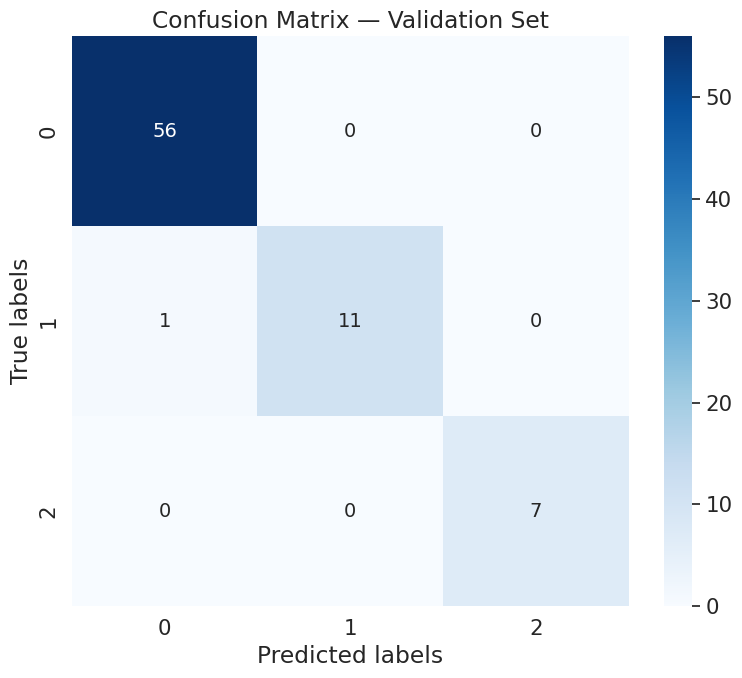

In [ ]:
val_preds, val_targets = study_subsequence(8, X_val, y_val, rnn_model) #input should be a number from 1 to 33

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

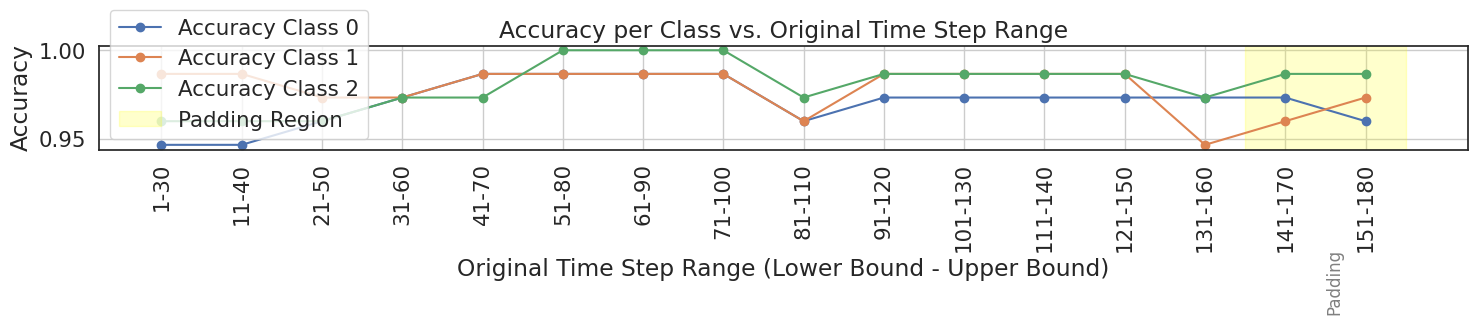

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np # Ensure numpy is imported for array operations

acc_0 = []
acc_1 = []
acc_2 = []
lower_bounds = []
upper_bounds = []
x_labels = [] # List to store custom x-axis labels


# Recalculate total_subsequences based on the actual X_val generation parameters
# This ensures the loop runs for the correct number of subsequences (16 in this case)
padding_len_for_xval = (WINDOW_SIZE - (160 % WINDOW_SIZE)) % WINDOW_SIZE
padded_len_for_xval = 160 + padding_len_for_xval
total_subsequences_to_plot = floor((padded_len_for_xval - WINDOW_SIZE) / STRIDE) + 1
total_subsequences_to_plot = int(total_subsequences_to_plot)

for i in range(total_subsequences_to_plot): # Iterate based on actual number of subsequences per sample (which is 16)
    # Call study_subsequence with 1-based index as it expects
    preds, targets = study_subsequence(i+1, X_val, y_val, rnn_model)

    # Calculate confusion matrix for the current subsequence
    cm = confusion_matrix(targets, preds, labels=[0, 1, 2])

    # Calculate per-class accuracy manually from the confusion matrix
    total_samples = np.sum(cm)
    if total_samples == 0: # Handle empty target/prediction sets
        acc_0.append(0.0)
        acc_1.append(0.0)
        acc_2.append(0.0)
    else:
        # Accuracy for Class 0
        tp_0 = cm[0, 0]
        tn_0 = np.sum(cm[1:, 1:]) # Sum of all elements not in row 0 and not in column 0
        acc_0.append((tp_0 + tn_0) / total_samples)

        # Accuracy for Class 1
        tp_1 = cm[1, 1]
        tn_1 = cm[0,0] + cm[0,2] + cm[2,0] + cm[2,2] # Sum of elements not in row 1 and not in column 1
        acc_1.append((tp_1 + tn_1) / total_samples)

        # Accuracy for Class 2
        tp_2 = cm[2, 2]
        tn_2 = np.sum(cm[:2, :2]) # Sum of elements not in row 2 and not in column 2
        acc_2.append((tp_2 + tn_2) / total_samples)

    # Calculate lower and upper bounds for the original time steps (0-indexed)
    # Use ACTUAL_XVAL_STRIDE and ACTUAL_XVAL_WINDOW_SIZE for accurate labels
    lower_bound = i * STRIDE + 1
    upper_bound = lower_bound + WINDOW_SIZE - 1

    lower_bounds.append(lower_bound)
    upper_bounds.append(upper_bound)

    # Create a string label for the x-axis
    x_labels.append(f"{lower_bound}-{upper_bound}")


# Plot the errors
plt.figure(figsize=(15, 9)) # Increased figure size for better label readability
plt.plot(range(total_subsequences_to_plot), acc_0, marker='o', linestyle='-', label='Accuracy Class 0')
plt.plot(range(total_subsequences_to_plot), acc_1, marker='o', linestyle='-', label='Accuracy Class 1')
plt.plot(range(total_subsequences_to_plot), acc_2, marker='o', linestyle='-', label='Accuracy Class 2')

plt.xlabel('Original Time Step Range (Lower Bound - Upper Bound)')
plt.ylabel('Accuracy') # Changed label to Accuracy
plt.title('Accuracy per Class vs. Original Time Step Range') # Changed title to Accuracy per Class

# Set custom x-axis ticks and labels
plt.xticks(range(total_subsequences_to_plot), x_labels, rotation=90) # Use x_labels for ticks, rotate for readability

plt.grid(True)

# Find the index where the upper bound first exceeds original_seq_len (length of original data)
padding_start_index = -1
for i, ub in enumerate(upper_bounds):
    if ub > 160:
        padding_start_index = i
        break

# If padding exists, add a shaded region and annotation
if padding_start_index != -1:
    # Shade the area from the start of padding subsequences to the end
    plt.axvspan(padding_start_index - 0.5, len(acc_0) - 0.5, color='yellow', alpha=0.2, label='Padding Region')

    # Add "padding" annotation
    # Position the text near the start of the shaded region
    plt.text(padding_start_index + 0.5, np.max(acc_0) * 0.9, 'Padding', # Use np.max for current list
             fontsize=12, color='gray', rotation=90, verticalalignment='top')

plt.legend()
plt.tight_layout() # Adjust layout to prevent labels overlapping
plt.show()

In [ ]:
rnn_model.eval() # Imposta il modello in modalità valutazione

all_flat_predictions = []
with torch.no_grad(): # Disabilita il calcolo dei gradienti per l'inferenza
    for inputs in all_sequences_loader:
        inputs = inputs[0].to(device) # Gli input sono in una tupla dal DataLoader
        outputs = rnn_model(inputs)
        _, predicted_classes = torch.max(outputs, 1)
        all_flat_predictions.extend(predicted_classes.cpu().numpy().tolist())

all_flat_predictions = np.array(all_flat_predictions)

# --- 3. Definizione delle sottosequenze per Majority Voting e Tie-breaking ---
# **MODIFICA QUI:** Definisci le 4 sottosequenze (1-indexed) per il voting a maggioranza.
# Ogni sottosequenza deve avere lunghezza WINDOW_SIZE (30 timesteps).
# start_timestep - 1 deve essere un multiplo di STRIDE (10).
subsequences_for_voting = [
     (61, 90),
     (51, 80),  # Esempio: start_ts=71 (0-indexed 70), end_ts=100 (0-indexed 99). Lunghezza 30. (70/10=7 -> k=7)
     (121, 150),
     (71, 100)
]

# **MODIFICA QUI:** Definisci la sottosequenza preferenziale (1-indexed) per il tie-breaking.
preferential_subsequence = (61, 90) # Esempio: start_ts=51 (0-indexed 50), end_ts=80 (0-indexed 79). Lunghezza 30. (50/10=5 -> k=5)

# Get unique sample indices from the test set
unique_users = X_test['sample_index'].unique()
original_sample_len = 160

# Calcola il numero di sottosequenze generate per *ogni singolo campione* dall'intera build_sequences_test
padding_len_per_sample = WINDOW_SIZE - (original_sample_len % WINDOW_SIZE)
if padding_len_per_sample == WINDOW_SIZE: # Se non c'è bisogno di padding, non aggiungere una finestra extra
    padding_len_per_sample = 0
padded_len_per_sample = original_sample_len + padding_len_per_sample
total_subsequences_per_original_sample = int(floor((padded_len_per_sample - WINDOW_SIZE) / STRIDE) + 1)

final_predictions = []
from collections import Counter

print("Applicazione del Majority Voting e Tie-breaking...")
for i, sample_id in enumerate(unique_users):
    # Estrai le previsioni per il campione corrente da tutte le sottosequenze
    sample_predictions_start_idx = i * total_subsequences_per_original_sample
    sample_predictions_end_idx = sample_predictions_start_idx + total_subsequences_per_original_sample
    current_sample_all_predictions = all_flat_predictions[sample_predictions_start_idx:sample_predictions_end_idx]

    # Raccogli le previsioni per le sottosequenze di voting
    votes = []
    for start_ts_1idx, end_ts_1idx in subsequences_for_voting:
        start_ts_0idx = start_ts_1idx - 1
        # Calcola l'indice k della sottosequenza relativa al campione
        # Questo k è l'indice della sottosequenza all'interno delle 'total_subsequences_per_original_sample'
        relative_subsequence_k = start_ts_0idx // STRIDE

        if relative_subsequence_k < len(current_sample_all_predictions):
            votes.append(current_sample_all_predictions[relative_subsequence_k])
        else:
            # Questo caso non dovrebbe accadere se le sottosequenze sono state definite correttamente
            # per rientrare nella lunghezza del campione originale (anche se padded).
            # Per sicurezza, si potrebbe gestire con un log o un valore di default.
            print(f"Attenzione: Sottosequenza di voting (start_ts={start_ts_1idx}) fuori dai limiti per sample_id {sample_id}.")
            # Potresti voler aggiungere un voto neutro o la predizione di una sottosequenza vicina.
            # Per ora, si assume che tutte le sottosequenze di voting siano valide.

    # Conta i voti per ciascuna classe
    vote_counts = Counter(votes)

    # Trova il numero massimo di voti
    max_votes = 0
    if vote_counts:
        max_votes = max(vote_counts.values())

    # Trova le classi che hanno ricevuto il massimo dei voti
    majority_classes = [cls for cls, count in vote_counts.items() if count == max_votes]

    if len(majority_classes) == 1:
        # Nessun pareggio, usa la classe di maggioranza
        final_predictions.append(majority_classes[0])
    else:
        # C'è un pareggio, usa la predizione della sottosequenza preferenziale
        pref_start_ts_1idx, _ = preferential_subsequence
        pref_start_ts_0idx = pref_start_ts_1idx - 1
        relative_pref_subsequence_k = pref_start_ts_0idx // STRIDE

        if relative_pref_subsequence_k < len(current_sample_all_predictions):
            final_predictions.append(current_sample_all_predictions[relative_pref_subsequence_k])
        else:
            print(f"Attenzione: Sottosequenza preferenziale (start_ts={pref_start_ts_1idx}) fuori dai limiti per sample_id {sample_id}.")
            # In caso di errore anche qui, potresti voler scegliere la prima classe di maggioranza
            final_predictions.append(majority_classes[0] if majority_classes else 0) # Default a 0 (no_pain) se non ci sono voti validi


# --- 4. Generazione del file di Submission ---

# Definisci una mappatura dalle previsioni numeriche ai livelli di dolore
pain_level_mapping = {
    0: "no_pain",
    1: "low_pain",
    2: "high_pain"
}

# Mappa le previsioni numeriche ai livelli di dolore
pain_levels = [pain_level_mapping[pred] for pred in final_predictions]

# Crea un DataFrame per il submission
submission_df = pd.DataFrame({
    'sample_index': unique_users, # Usa gli ID unici dei campioni come colonna sample_index
    'label': pain_levels
})

# Definisci il nome del file di submission
submission_filename = 'cnnlstm_tommi.csv'

# Salva il DataFrame in un file CSV senza l'indice
submission_df.to_csv(submission_filename, index=False)

print(f"File di submission '{submission_filename}' creato con successo.")
display(submission_df.head())

Applicazione del Majority Voting e Tie-breaking...
File di submission 'cnnlstm_tommi.csv' creato con successo.


,sample_index,label
0,0,no_pain
1,1,no_pain
2,2,no_pain
3,3,no_pain
4,4,no_pain
